# 1. Import Library

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Input, LSTM, Dense
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

Pandas: 3.0.3
NumPy: 2.5.1
TensorFlow: 2.21.0


# 2. Memuat Data AQI

In [4]:
df = pd.read_parquet(
    "data/dataset_aqi_gabungan.parquet",
    columns=["updated_at", "device", "aqi"]
)

df["updated_at"] = pd.to_datetime(df["updated_at"])

df_sensor = df[
    df["device"] == "Jl. Lapangan Rajawali"
].copy()

aqi_harian = (
    df_sensor
    .set_index("updated_at")["aqi"]
    .resample("D")
    .mean()
    .dropna()
)

aqi_harian = aqi_harian.loc[
    "2025-11-03":"2026-02-18"
]

print("Jumlah data:", len(aqi_harian))
print("Tanggal awal:", aqi_harian.index.min())
print("Tanggal akhir:", aqi_harian.index.max())
print("Nilai kosong:", aqi_harian.isna().sum())

Jumlah data: 108
Tanggal awal: 2025-11-03 00:00:00
Tanggal akhir: 2026-02-18 00:00:00
Nilai kosong: 0


# 3. Membagi data training dan testing

In [5]:
# Pembagian data secara kronologis
jumlah_train = 86

train = aqi_harian.iloc[:jumlah_train]
test = aqi_harian.iloc[jumlah_train:]

print("Data training:", len(train))
print("Periode training:", train.index.min(), "sampai", train.index.max())

print("\nData testing:", len(test))
print("Periode testing:", test.index.min(), "sampai", test.index.max())

Data training: 86
Periode training: 2025-11-03 00:00:00 sampai 2026-01-27 00:00:00

Data testing: 22
Periode testing: 2026-01-28 00:00:00 sampai 2026-02-18 00:00:00


# 4. Melatih model sarima terbaik

In [18]:

# Melatih ulang SARIMA dengan konfigurasi kandidat terbaik
model_sarima_final = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(0, 0, 1, 7),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

hasil_sarima_final = model_sarima_final.fit(disp=False)

print("AIC:", hasil_sarima_final.aic)
print("BIC:", hasil_sarima_final.bic)
print("Trend:", hasil_sarima_final.model.trend)


d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


AIC: 592.2613593883818
BIC: 603.9803864976502
Trend: c


In [19]:
print("Tipe train:", type(train))
print("Jumlah data train:", len(train))
print("Tanggal awal:", train.index.min())
print("Tanggal akhir:", train.index.max())

print("\nLima data pertama:")
print(train.head())

print("\nStatistik train:")
print(train.describe())

Tipe train: <class 'pandas.Series'>
Jumlah data train: 86
Tanggal awal: 2025-11-03 00:00:00
Tanggal akhir: 2026-01-27 00:00:00

Lima data pertama:
updated_at
2025-11-03    67.871795
2025-11-04    57.123967
2025-11-05    42.314050
2025-11-06     8.365854
2025-11-07    27.290598
Name: aqi, dtype: float64

Statistik train:
count    86.000000
mean     25.890279
std      15.845934
min       5.381503
25%      13.954168
50%      22.158951
75%      33.412612
max      67.871795
Name: aqi, dtype: float64


In [20]:
print("Order:", hasil_sarima_final.model.order)
print("Seasonal order:", hasil_sarima_final.model.seasonal_order)
print("Trend:", hasil_sarima_final.model.trend)
print("AIC:", hasil_sarima_final.aic)
print("BIC:", hasil_sarima_final.bic)

print("\nParameter:")
print(hasil_sarima_final.params)

Order: (1, 0, 1)
Seasonal order: (0, 0, 1, 7)
Trend: c
AIC: 592.2613593883818
BIC: 603.9803864976502

Parameter:
intercept     12.725327
ar.L1          0.452317
ma.L1          0.169420
ma.S.L7       -0.095861
sigma2       112.477530
dtype: float64


In [6]:
# Model SARIMA terbaik dari eksperimen sebelumnya
model_sarima = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(0, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

hasil_sarima = model_sarima.fit(disp=False)

print(hasil_sarima.summary())

d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                     
Dep. Variable:                               aqi   No. Observations:                   86
Model:             SARIMAX(1, 0, 1)x(0, 0, 1, 7)   Log Likelihood                -299.699
Date:                           Sun, 18 Oct 2026   AIC                            607.398
Time:                                   21:15:52   BIC                            616.773
Sample:                               11-03-2025   HQIC                           611.148
                                    - 01-27-2026                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9163      0.038     24.392      0.000       0.843       0.990
ma.L1         -0.1220      0.123     -0.994

# 5. Menghitung residual training

In [21]:

# 1. Prediksi fitted SARIMA pada data training
prediksi_train_sarima_final = hasil_sarima_final.get_prediction(
    start=0,
    end=len(train) - 1
).predicted_mean

# 2. Samakan indeks dengan data training
prediksi_train_sarima_final.index = train.index

# 3. Hitung residual training
residual_train_final = train - prediksi_train_sarima_final

# 4. Periksa hasil
print("Jumlah residual:", len(residual_train_final))
print("Residual kosong:", residual_train_final.isna().sum())
print("Rata-rata residual:", residual_train_final.mean())
print("Standar deviasi residual:", residual_train_final.std())

print("\nLima residual pertama:")
print(residual_train_final.head())


Jumlah residual: 86
Residual kosong: 0
Rata-rata residual: 1.7630730093290206
Standar deviasi residual: 14.459254020972287

Lima residual pertama:
updated_at
2025-11-03    67.871795
2025-11-04    13.699091
2025-11-05     3.750335
2025-11-06   -23.498898
2025-11-07    10.781703
dtype: float64


# 6. Membuat data sequence residual LSTM

Residual dihitung dari:
et=yt-y't


Keterangan:
- yt: nilai AQI aktual pada data training.
- y't: nilai estimasi AQI dari SARIMA.
- et: residual yang akan dipelajari oleh LSTM.

In [22]:

# Panjang sequence: 7 hari
look_back = 7

# Mengubah residual menjadi array dua dimensi
residual_values_final = residual_train_final.to_numpy().reshape(-1, 1)

# Normalisasi residual training
scaler_residual_final = MinMaxScaler(feature_range=(0, 1))
residual_scaled_final = scaler_residual_final.fit_transform(
    residual_values_final
)

# Membuat sequence untuk LSTM
X_residual_final = []
y_residual_final = []

for i in range(look_back, len(residual_scaled_final)):
    X_residual_final.append(
        residual_scaled_final[i-look_back:i, 0]
    )
    y_residual_final.append(
        residual_scaled_final[i, 0]
    )

X_residual_final = np.array(X_residual_final)
y_residual_final = np.array(y_residual_final)

# Mengubah bentuk menjadi (sampel, timestep, fitur)
X_residual_final_lstm = X_residual_final.reshape(
    X_residual_final.shape[0],
    X_residual_final.shape[1],
    1
)

print("Jumlah sequence:", X_residual_final_lstm.shape[0])
print("Bentuk X:", X_residual_final_lstm.shape)
print("Bentuk y:", y_residual_final.shape)


Jumlah sequence: 79
Bentuk X: (79, 7, 1)
Bentuk y: (79,)


menjadi 79 sequence Karena 7 residual pertama digunakan sebagai input untuk memprediksi residual ke-8. Proses ini berlanjut sampai residual ke-86.

# 7. Membangun dan melatih LSTM residual

- LSTM 32 unit: mempelajari pola residual dari tujuh hari sebelumnya.
- Dense(1): menghasilkan satu prediksi residual.
- EarlyStopping: menghentikan pelatihan jika val_loss tidak membaik selama 10 epoch.
- Seed 42: membantu membuat hasil eksperimen lebih konsisten saat dijalankan ulang.

In [23]:

# Menetapkan seed agar eksperimen lebih konsisten
tf.keras.utils.set_random_seed(42)

# Membangun model LSTM residual
model_residual_final = Sequential([
    Input(shape=(look_back, 1)),
    LSTM(32, activation="tanh"),
    Dense(1)
])

model_residual_final.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error"
)

early_stop_final = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_residual_final = model_residual_final.fit(
    X_residual_final_lstm,
    y_residual_final,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop_final],
    verbose=1
)

print("Pelatihan LSTM residual selesai.")
print("Jumlah epoch:", len(history_residual_final.history["loss"]))
print(
    "Validation loss terbaik:",
    min(history_residual_final.history["val_loss"])
)


Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0697 - val_loss: 0.0234
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0377 - val_loss: 0.0077
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0223 - val_loss: 0.0040
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0203 - val_loss: 0.0055
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0201 - val_loss: 0.0044
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0190 - val_loss: 0.0039
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0193 - val_loss: 0.0040
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0194 - val_loss: 0.0039
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0193 - val_loss: 0.0040
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0192 - val_loss: 0.0040
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0191 - val_loss: 0.0040
Epoch 12/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0191 - val_lo

# 8. Memprediksi residual 22 hari kedepan

In [24]:

# Mengambil 7 residual training terakhir
riwayat_residual_final = list(
    residual_scaled_final[-look_back:, 0]
)

prediksi_residual_scaled_final = []

# Prediksi residual secara rekursif untuk 22 hari
for _ in range(len(test)):
    input_lstm = np.array(
        riwayat_residual_final[-look_back:]
    ).reshape(1, look_back, 1)

    prediksi_satu_hari = model_residual_final.predict(
        input_lstm, verbose=0
    )[0, 0]

    prediksi_residual_scaled_final.append(
        prediksi_satu_hari
    )

    # Prediksi hari ini menjadi input untuk hari berikutnya
    riwayat_residual_final.append(prediksi_satu_hari)

# Mengembalikan prediksi ke skala residual asli
prediksi_residual_final = scaler_residual_final.inverse_transform(
    np.array(prediksi_residual_scaled_final).reshape(-1, 1)
).flatten()

prediksi_residual_test_final = pd.Series(
    prediksi_residual_final,
    index=test.index,
    name="Prediksi_Residual_LSTM"
)

print("Jumlah prediksi residual:", len(prediksi_residual_test_final))
print("\nLima prediksi residual pertama:")
print(prediksi_residual_test_final.head())


Jumlah prediksi residual: 22

Lima prediksi residual pertama:
updated_at
2026-01-28    0.213561
2026-01-29    0.590103
2026-01-30    0.660548
2026-01-31    0.654808
2026-02-01    0.564073
Name: Prediksi_Residual_LSTM, dtype: float32


# 9. Menggabungkan prediksi SARIMA dan LSTM

y(hybrid)t = y(sarima)t+e(LSTM)t

In [25]:

# 1. Prediksi SARIMA untuk 22 hari testing
prediksi_sarima_final = hasil_sarima_final.get_forecast(
    steps=len(test)
).predicted_mean

prediksi_sarima_final.index = test.index

# 2. Gabungkan SARIMA dengan residual LSTM
prediksi_hybrid_final = (
    prediksi_sarima_final.to_numpy()
    + prediksi_residual_test_final.to_numpy()
)

# 3. Buat tabel hasil prediksi
hasil_hybrid_final = pd.DataFrame({
    "AQI_Aktual": test.to_numpy(),
    "Prediksi_SARIMA": prediksi_sarima_final.to_numpy(),
    "Prediksi_Residual_LSTM": prediksi_residual_test_final.to_numpy(),
    "Prediksi_Hybrid": prediksi_hybrid_final
}, index=test.index)

# 4. Periksa hasil
print("Jumlah data:", len(hasil_hybrid_final))
display(hasil_hybrid_final.head(10))


Jumlah data: 22


,AQI_Aktual,Prediksi_SARIMA,Prediksi_Residual_LSTM,Prediksi_Hybrid
updated_at,,,,
2026-01-28,17.951087,27.489536,0.213561,27.703097
2026-01-29,31.074866,25.537708,0.590103,26.127811
2026-01-30,27.474359,24.426776,0.660548,25.087325
2026-01-31,10.000000,23.711513,0.654808,24.366321
2026-02-01,1.640000,23.678759,0.564073,24.242832
2026-02-02,10.356688,22.049106,0.594010,22.643116
2026-02-03,8.025478,22.570980,-0.009648,22.561332
2026-02-04,4.783439,22.953928,0.022457,22.976385
2026-02-05,12.936306,23.107773,-0.009128,23.098645


- LSTM memberikan koreksi kecil terhadap prediksi SARIMA. Pada beberapa hari berikutnya, koreksinya juga relatif kecil dibandingkan selisih antara prediksi SARIMA dan AQI aktual.


# 10. Evaluasi model SARIMA dan Hybrid

In [27]:
# Menyamakan nama variabel untuk kompatibilitas dengan sel sebelumnya
hasil_hybrid = hasil_hybrid_final.copy()

print("Variabel hasil_hybrid berhasil dibuat.")
print("Jumlah data:", len(hasil_hybrid))
display(hasil_hybrid.head())

Variabel hasil_hybrid berhasil dibuat.
Jumlah data: 22


,AQI_Aktual,Prediksi_SARIMA,Prediksi_Residual_LSTM,Prediksi_Hybrid
updated_at,,,,
2026-01-28,17.951087,27.489536,0.213561,27.703097
2026-01-29,31.074866,25.537708,0.590103,26.127811
2026-01-30,27.474359,24.426776,0.660548,25.087325
2026-01-31,10.000000,23.711513,0.654808,24.366321
2026-02-01,1.640000,23.678759,0.564073,24.242832


In [26]:

# Menghitung metrik evaluasi SARIMA dan Hybrid final
aktual_final = hasil_hybrid_final["AQI_Aktual"].to_numpy()
sarima_final = hasil_hybrid_final["Prediksi_SARIMA"].to_numpy()
hybrid_final = hasil_hybrid_final["Prediksi_Hybrid"].to_numpy()

def evaluasi_model(aktual, prediksi):
    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    # Menghindari pembagian dengan nol
    mask = aktual != 0
    mape = np.mean(
        np.abs(
            (aktual[mask] - prediksi[mask]) / aktual[mask]
        )
    ) * 100

    return mae, rmse, mape

mae_s, rmse_s, mape_s = evaluasi_model(
    aktual_final, sarima_final
)

mae_h, rmse_h, mape_h = evaluasi_model(
    aktual_final, hybrid_final
)

tabel_evaluasi_final = pd.DataFrame({
    "Model": ["SARIMA", "Hybrid SARIMA-LSTM"],
    "MAE": [mae_s, mae_h],
    "RMSE": [rmse_s, rmse_h],
    "MAPE (%)": [mape_s, mape_h]
})

display(tabel_evaluasi_final.round(4))


,Model,MAE,RMSE,MAPE (%)
0,SARIMA,11.6583,12.8907,189.3380
1,Hybrid SARIMA-LSTM,11.6280,12.9141,190.1154


### Perubahan Kinerja untuk mengetahui apakah hybrid memperbaiki hasil SARIMA.

In [29]:
print(
    "Perubahan MAE (%):",
    round((mae_s - mae_h) / mae_s * 100, 2)
)

print(
    "Perubahan RMSE (%):",
    round((rmse_s - rmse_h) / rmse_s * 100, 2)
)

print(
    "Perubahan MAPE (%):",
    round((mape_s - mape_h) / mape_s * 100, 2)
)

Perubahan MAE (%): 0.26
Perubahan RMSE (%): -0.18
Perubahan MAPE (%): -0.41


- Hybrid SARIMA–LSTM menghasilkan perbaikan MAE sebesar 0,26%, tetapi belum memperbaiki RMSE dan MAPE. 
- Perubahan ini sangat kecil, sehingga belum menunjukkan peningkatan akurasi yang konsisten dibandingkan SARIMA.

# 11. hasil grafik perbandingan

In [36]:

# Tabel perbandingan sementara ketiga model
tabel_perbandingan_final = pd.DataFrame({
    "Model": [
        "SARIMA",
        "LSTM Multi-step",
        "Hybrid SARIMA-LSTM"
    ],
    "MAE": [
        11.6583,
        11.6430,
        11.6280
    ],
    "RMSE": [
        12.8907,
        12.9326,
        12.9141
    ],
    "MAPE (%)": [
        189.3380,
        189.7165,
        190.1154
    ]
})

tabel_perbandingan_final["Model"] = (
    tabel_perbandingan_final["Model"]
    .replace({"LSTM Multi-step": "LSTM"})
)

display(tabel_perbandingan_final.round(4))


,Model,MAE,RMSE,MAPE (%)
0,SARIMA,11.6583,12.8907,189.3380
1,LSTM,11.6430,12.9326,189.7165
2,Hybrid SARIMA-LSTM,11.6280,12.9141,190.1154


- SARIMA: menghasilkan RMSE dan MAPE terendah. Model ini memberikan hasil terbaik untuk kedua metrik tersebut.
- LSTM: memperoleh MAE sedikit lebih rendah daripada SARIMA, tetapi RMSE dan MAPE lebih tinggi.
- Hybrid SARIMA–LSTM: memperoleh MAE terendah, tetapi belum memberikan perbaikan pada RMSE dan MAPE dibandingkan SARIMA.

### Menyiapkan data 3 model

In [38]:
# Membaca prediksi LSTM multi-step dari file CSV
hasil_lstm_final = pd.read_csv(
    "prediksi_lstm.csv",
    parse_dates=["Tanggal"]
)

print("Jumlah data LSTM:", len(hasil_lstm_final))
print("Kolom:", hasil_lstm_final.columns.tolist())

display(hasil_lstm_final.head())

Jumlah data LSTM: 22
Kolom: ['updated_at', 'Tanggal', 'AQI_Aktual', 'AQI_Prediksi']


,updated_at,Tanggal,AQI_Aktual,AQI_Prediksi
0,0,2026-01-28,17.951087,22.553778
1,1,2026-01-29,31.074866,23.114206
2,2,2026-01-30,27.474359,23.989006
3,3,2026-01-31,10.000000,24.565088
4,4,2026-02-01,1.640000,23.880915


In [39]:

# Menyiapkan data untuk grafik perbandingan

# Prediksi SARIMA dan Hybrid berasal dari notebook 04
# Prediksi LSTM dibaca dari hasil LSTM multi-step notebook 03

hasil_lstm_final["Tanggal"] = pd.to_datetime(
    hasil_lstm_final["Tanggal"]
)

hasil_lstm_plot = hasil_lstm_final.set_index("Tanggal")

# Menggunakan tanggal pengujian yang sama
tanggal_test = hasil_hybrid_final.index

hasil_lstm_plot = hasil_lstm_plot.reindex(tanggal_test)

# Memastikan jumlah data sesuai
print("Jumlah data SARIMA dan Hybrid:", len(hasil_hybrid_final))
print("Jumlah data LSTM:", len(hasil_lstm_plot))
print("Tanggal awal:", tanggal_test.min())
print("Tanggal akhir:", tanggal_test.max())


Jumlah data SARIMA dan Hybrid: 22
Jumlah data LSTM: 22
Tanggal awal: 2026-01-28 00:00:00
Tanggal akhir: 2026-02-18 00:00:00


### membuat grafik 3 model

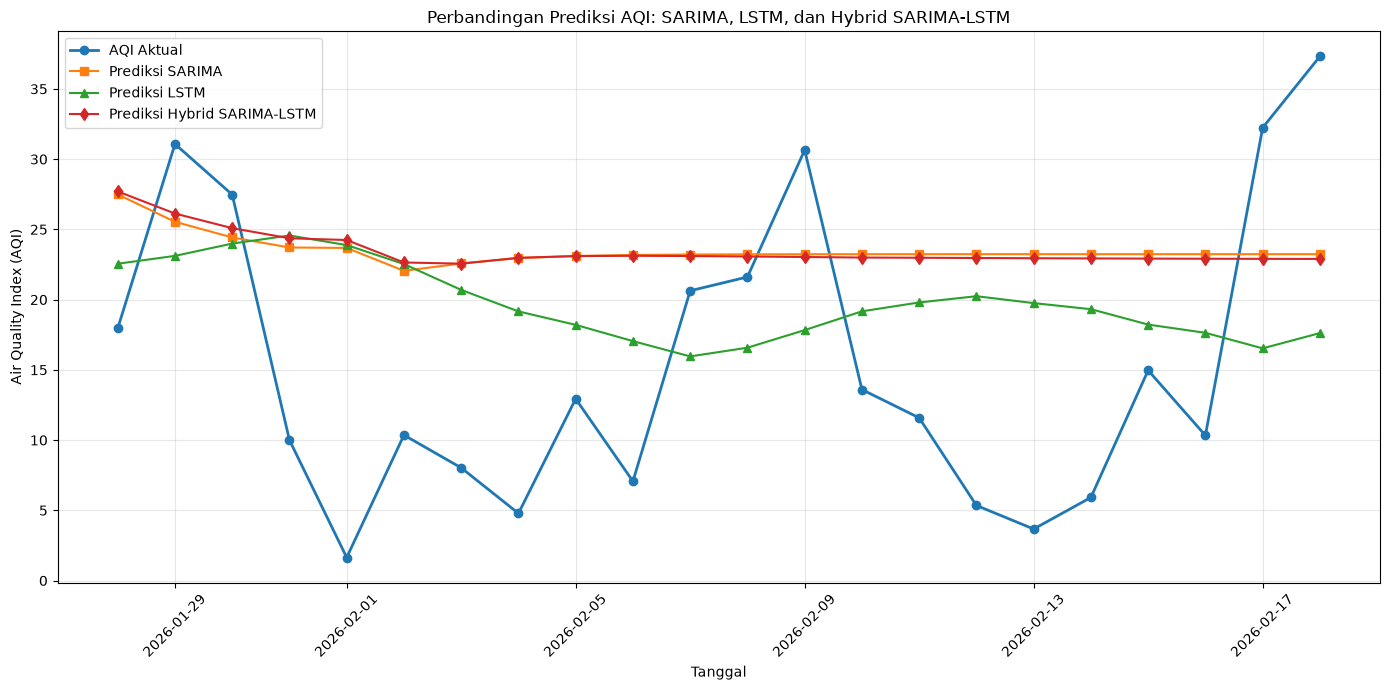

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

# AQI aktual
plt.plot(
    hasil_hybrid_final.index,
    hasil_hybrid_final["AQI_Aktual"],
    marker="o",
    linewidth=2,
    label="AQI Aktual"
)

# SARIMA
plt.plot(
    hasil_hybrid_final.index,
    hasil_hybrid_final["Prediksi_SARIMA"],
    marker="s",
    label="Prediksi SARIMA"
)

# LSTM
plt.plot(
    hasil_lstm_plot.index,
    hasil_lstm_plot["AQI_Prediksi"],
    marker="^",
    label="Prediksi LSTM"
)

# Hybrid SARIMA-LSTM
plt.plot(
    hasil_hybrid_final.index,
    hasil_hybrid_final["Prediksi_Hybrid"],
    marker="d",
    label="Prediksi Hybrid SARIMA-LSTM"
)

plt.title(
    "Perbandingan Prediksi AQI: SARIMA, LSTM, dan Hybrid SARIMA-LSTM"
)
plt.xlabel("Tanggal")
plt.ylabel("Air Quality Index (AQI)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### hasil
- Prediksi SARIMA cenderung menurun pada awal periode, kemudian stabil di sekitar AQI 23. Model belum mengikuti fluktuasi aktual secara memadai, terutama saat AQI turun ke nilai rendah atau meningkat tajam
- LSTM menunjukkan pola prediksi yang lebih bervariasi dibandingkan SARIMA. Namun, prediksi tetap cenderung berada pada rentang sekitar 16–25 dan belum menangkap lonjakan AQI aktual di atas 30 maupun beberapa penurunan tajam.
- Prediksi hybrid mendekati SARIMA setelah beberapa hari pertama. Koreksi residual LSTM belum menghasilkan perubahan prediksi yang cukup besar untuk mengikuti seluruh fluktuasi AQI aktual.

| Metrik | SARIMA | LSTM | Hybrid SARIMA–LSTM |
|---|---:|---:|---:|
| MAE | 11,6583 | 11,6430 | 11,6280 |
| RMSE | 12,8907 | 12,9326 | 12,9141 |
| MAPE | 189,3380% | 189,7165% | 190,1154% |

Hasil evaluasi menunjukkan bahwa:

- **MAE:** Hybrid SARIMA–LSTM memperoleh nilai terendah sebesar 11,6280.
- **RMSE:** SARIMA memperoleh nilai terendah sebesar 12,8907.
- **MAPE:** SARIMA memperoleh nilai terendah sebesar 189,3380%.

Dengan demikian, belum ada model yang unggul pada seluruh metrik evaluasi. Model hybrid memiliki MAE terendah, tetapi belum menunjukkan peningkatan yang konsisten pada RMSE dan MAPE dibandingkan SARIMA.

Nilai MAPE yang tinggi perlu ditafsirkan secara hati-hati karena nilai AQI aktual yang mendekati nol dapat memperbesar persentase kesalahan prediksi.